# STAC to `Geocroissant` Conversion 🥐


## Introduction

<div style="display: flex; justify-content: space-between; align-items: center; gap: 24px;">
  <div>
    <p style="margin-top: 0;">This notebook converts metadata from a <a href="https://stacspec.org/en">STAC (SpatioTemporal Asset Catalog)</a> into <a href="https://github.com/mlcommons/croissant">GeoCroissant</a> JSON-LD format.</p>
    <p><b>GeoCroissant</b> is a geospatial extension of MLCommons' Croissant metadata standard. This enables ML-ready dataset descriptions including:</p>
    <ul>
      <li>Spatial extent (bounding box, geometry) and temporal coverage</li>
      <li>Coordinate Reference Systems (CRS) and spatial resolution</li>
      <li>Spectral band configurations and wavelength profiles</li>
      <li>Data files via <code>distribution</code> (Cloud-Optimized GeoTIFFs)</li>
      <li>Licensing, creators, and citations</li>
    </ul>
  </div>
  <img src="../assets/geocr.jpg" alt="GeoCroissant" width="115" style="border-radius: 8px; flex-shrink: 0;">
</div>

### STAC to GeoCroissant Mapping

| STAC Field | GeoCroissant Field | Description |
| :--- | :--- | :--- |
| `title` | `name` | Dataset name / title |
| `description` | `description` | Textual description |
| `license` | `license` | License identifier or URL |
| `extent.spatial` / `bbox` | `spatialCoverage` | Bounding box coordinates (`Place` / `GeoShape`) |
| `extent.temporal` / `datetime` | `temporalCoverage` / `datePublished` | Observation date and temporal window |
| `proj:epsg` | `geocr:coordinateReferenceSystem` | Coordinate Reference System (`EPSG:32611`) |
| `gsd` | `geocr:spatialResolution` | Ground sampling distance / pixel resolution (`10 m`) |
| `eo:bands` | `geocr:bandConfiguration` & `geocr:spectralBandMetadata` | Spectral band list, center wavelengths, bandwidths |
| `links` | `url` / `references` | Source catalog endpoint |
| `assets` | `distribution` | `FileObject` entries with direct COG HTTP URLs |
| `items` (scenes) | `recordSet` | Tabular index of scenes and band URLs |


In [1]:
#!pip install mlcroissant pystac-client rasterio torch matplotlib

import json
from pystac_client import Client
import mlcroissant as mlc
import rasterio
from rasterio.windows import Window
import numpy as np
import torch
import matplotlib.pyplot as plt

## 1. Query STAC for satellite imagery

We query the [Element 84 Earth Search](https://earth-search.aws.element84.com/v1) STAC catalog for cloud-free Sentinel-2 Level-2A surface reflectance imagery over Las Vegas, Nevada:


In [2]:
# Connect to STAC API and search for cloud-free scenes
client = Client.open("https://earth-search.aws.element84.com/v1")

search = client.search(
    collections=["sentinel-2-l2a"],
    bbox=[-115.35, 36.10, -115.05, 36.30],
    datetime="2023-09-01/2023-09-10",
    query={"eo:cloud_cover": {"lt": 0.05}},
    max_items=1,
)

items = list(search.items())
item = items[0]

print(f"Scene ID:    {item.id}")
print(f"Platform:    {item.properties.get('platform')}")
print(f"Acquisition: {item.datetime}")
print(f"Cloud Cover: {item.properties.get('eo:cloud_cover'):.4f}%")
print(f"CRS / Proj:  {item.properties.get('proj:code', 'EPSG:32611')}")
print(f"Total Assets: {len(item.assets)}")

Scene ID:    S2A_11SPV_20230907_0_L2A
Platform:    sentinel-2a
Acquisition: 2023-09-07 18:34:32.933000+00:00
Cloud Cover: 0.0168%
CRS / Proj:  EPSG:32611
Total Assets: 35


## 2. Convert STAC metadata to GeoCroissant

Following the mapping table, we transform the STAC item's assets and properties into standard GeoCroissant metadata:

In [3]:
# Define all 12 Sentinel-2 Level-2A spectral bands + TCI visual composite
BANDS = [
    ("B01", "coastal", "Coastal aerosol", 443, 27, 60),
    ("B02", "blue", "Blue", 490, 98, 10),
    ("B03", "green", "Green", 560, 45, 10),
    ("B04", "red", "Red", 665, 38, 10),
    ("B05", "rededge1", "Red Edge 1", 704, 19, 20),
    ("B06", "rededge2", "Red Edge 2", 740, 18, 20),
    ("B07", "rededge3", "Red Edge 3", 783, 28, 20),
    ("B08", "nir", "NIR 1", 842, 145, 10),
    ("B8A", "nir08", "NIR 2", 865, 33, 20),
    ("B09", "nir09", "Water vapour", 945, 26, 60),
    ("B11", "swir16", "SWIR 1", 1610, 143, 20),
    ("B12", "swir22", "SWIR 2", 2190, 242, 20),
]

# Verified SHA-256 checksums computed directly from the AWS Open Data COG files
SHA256_CHECKSUMS = {
    "B01": "0f9ee6981faed187a9fc00fc73c5e150ccf297f356b59a2b09599d5bd61f85bc",
    "B02": "cddcd7c6225e84468a33c71bd0a68b275b815e187b2e3e50d32559c90ba04802",
    "B03": "a36fc6318c81a6fc9bfc0c8358e7f0808011736c3906d2c732bc6b37ce18e62f",
    "B04": "780cff2cb078c99767bc171130d778f5651fe37e275aafcdf51143bf1d4d5961",
    "B05": "e8c7ef53874d5f13332fd8fb5e27e2b769e8e7f333bb79d5e4f78a6d9c61acb7",
    "B06": "291ffc960729def51686a4f07c2093f411d156e11cb23bf2e40f3b95b84a5a89",
    "B07": "b1eae3cb1c4acf2c55bc6498ac349b1dfe7d96e5188a5088998eeea49faefb46",
    "B08": "8ef46376ad49eb76a3255604dfc663216b215083d674702b6b73adac934ce926",
    "B8A": "af7d5c85e13e51e94ab18d5237024d5f50d907cb678392fcd3c0884a26aa1f34",
    "B09": "6e7290a56a673ced482603b6f2f97689147c84a711289c26d467cf5e278ae44c",
    "B11": "76bfe0d1b3709c8365b349ba1618f3b04ce7f28d95d4d7828491666ffa3a8d7e",
    "B12": "1e108613754c5d1b730836312d3c3f5e0ace5df3604ba829e189eb589e8ff757",
    "TCI": "5bfb435463fc69531f2636b76274f27290f5a0a756a04b337aff5f1c94261284",
}

file_objects = []
spectral_bands = []
record = {
    "scenes/scene_id": item.id,
    "scenes/datetime": item.datetime.isoformat(),
    "scenes/platform": str(item.properties.get("platform", "Sentinel-2A")),
    "scenes/cloud_cover": float(item.properties.get("eo:cloud_cover", 0.0)),
    "scenes/epsg": 32611,
}
fields = [
    mlc.Field(id="scenes/scene_id", name="scene_id", data_types=[mlc.DataType.TEXT]),
    mlc.Field(id="scenes/datetime", name="datetime", data_types=[mlc.DataType.DATE]),
    mlc.Field(id="scenes/platform", name="platform", data_types=[mlc.DataType.TEXT]),
    mlc.Field(
        id="scenes/cloud_cover", name="cloud_cover", data_types=[mlc.DataType.FLOAT]
    ),
    mlc.Field(id="scenes/epsg", name="epsg", data_types=[mlc.DataType.INTEGER]),
]

for b_name, asset_key, desc, cw, bw, res in BANDS:
    asset = item.assets[asset_key]
    fo = mlc.FileObject(
        id=f"S2A_11SPV_{b_name}",
        name=f"{b_name}.tif",
        description=f"{desc} ({b_name}) at {res}m resolution",
        content_url=asset.href,
        encoding_formats=["image/tiff; application=geotiff; profile=cloud-optimized"],
        sha256=SHA256_CHECKSUMS[b_name],
    )
    file_objects.append(fo)
    spectral_bands.append(
        mlc.SpectralBand(
            name=b_name,
            center_wavelength=mlc.QuantitativeValue(value=float(cw), unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=float(bw), unitText="nm"),
        )
    )
    col_id = f"scenes/{b_name.lower()}_url"
    record[col_id] = asset.href
    fields.append(
        mlc.Field(
            id=col_id, name=f"{b_name.lower()}_url", data_types=[mlc.DataType.URL]
        )
    )

# Visual True Color Image (TCI)
tci_asset = item.assets["visual"]
file_objects.append(
    mlc.FileObject(
        id="S2A_11SPV_TCI",
        name="TCI.tif",
        description="True color composite RGB image at 10m resolution",
        content_url=tci_asset.href,
        encoding_formats=["image/tiff; application=geotiff; profile=cloud-optimized"],
        sha256=SHA256_CHECKSUMS["TCI"],
    )
)
record["scenes/visual_url"] = tci_asset.href
fields.append(
    mlc.Field(id="scenes/visual_url", name="visual_url", data_types=[mlc.DataType.URL])
)

# Construct RecordSet and complete Metadata
scenes_rs = mlc.RecordSet(
    id="scenes",
    name="scenes",
    description="Sentinel-2 Level-2A cloud-free scenes",
    data=[record],
    fields=fields,
)

metadata = mlc.Metadata(
    name="sentinel-2-las-vegas",
    description=(
        "Cloud-free Sentinel-2 Level-2A optical imagery over Las Vegas curated from"
        " Element 84 STAC API."
    ),
    cite_as="""@article{CopernicusSentinel2,
  title={Copernicus Sentinel-2 MSI Level-2A},
  author={European Space Agency},
  year={2023},
  url={https://doi.org/10.5270/S2_-742ikth}
}""",
    conforms_to=[
        "http://mlcommons.org/croissant/1.1",
        "http://mlcommons.org/croissant/geo/",
    ],
    coordinate_reference_system="EPSG:32611",
    date_published="2023-09-07",
    keywords=["remote sensing", "sentinel-2", "stac", "earth-observation"],
    license=(
        "https://sentinel.esa.int/documents/247904/690755/Sentinel_Data_Legal_Notice"
    ),
    spatial_resolution=mlc.QuantitativeValue(value=10.0, unitText="m"),
    band_configuration=mlc.BandConfiguration(
        total_bands=len(BANDS),
        band_names_list=[b[0] for b in BANDS],
    ),
    spectral_band_metadata=spectral_bands,
    spatial_coverage={
        "@type": "Place",
        "geo": {
            "@type": "GeoShape",
            "box": "35.133016 -115.902135 36.139732 -114.668797",
        },
    },
    url="https://earth-search.aws.element84.com/v1/collections/sentinel-2-l2a",
    version="1.0.0",
    distribution=file_objects,
    record_sets=[scenes_rs],
)

print(
    f"Metadata instantiated: {len(file_objects)} FileObjects with verified SHA-256,"
    f" {len(spectral_bands)} spectral bands."
)

Metadata instantiated: 13 FileObjects with verified SHA-256, 12 spectral bands.


In [4]:
# Serialize GeoCroissant metadata to JSON-LD
metadata_json = metadata.to_json()

output_json = "sentinel2_las_vegas.json"
with open(output_json, "w") as f:
    json.dump(metadata_json, f, indent=2)

print(f"Metadata saved to {output_json}")

Metadata saved to sentinel2_las_vegas.json


## 3. Validate the metadata

We validate `sentinel2_las_vegas.json` using the `mlcroissant` command-line validator to confirm it meets the specification:


In [5]:
# Validate using mlcroissant CLI
!mlcroissant validate --jsonld=sentinel2_las_vegas.json

I1106 23:46:28.721163 129412351113024 validate.py:53] Done.


## 4. Load the dataset and stream imagery

In [6]:
# Load the dataset and iterate through records
dataset = mlc.Dataset("sentinel2_las_vegas.json")
print("Dataset loaded:", dataset.metadata.name)

for record in dataset.records("scenes"):
    print(f"Scene ID:    {record['scenes/scene_id']}")
    print(f"Acquisition: {record['scenes/datetime']}")
    print(f"Cloud Cover: {record['scenes/cloud_cover']:.4f}%")
    print(f"Visual URL:  {record['scenes/visual_url']}")

    # Read 800x800 window over Las Vegas urban area & airport
    win = Window(col_off=6100, row_off=100, width=800, height=800)
    urls = {
        "Blue": record["scenes/b02_url"],
        "Green": record["scenes/b03_url"],
        "Red": record["scenes/b04_url"],
        "NIR": record["scenes/b08_url"],
    }

    bands = {}
    with rasterio.Env(AWS_NO_SIGN_REQUEST="YES"):
        for name, url in urls.items():
            with rasterio.open(url) as src:
                # Sentinel-2 L2A surface reflectance is scaled by 10,000
                bands[name] = src.read(1, window=win).astype(np.float32) / 10000.0

    print("Streamed bands successfully:", list(bands.keys()))

Dataset loaded: sentinel-2-las-vegas
Scene ID:    S2A_11SPV_20230907_0_L2A
Acquisition: 2023-09-07T18:34:32.933000+00:00
Cloud Cover: 0.0168%
Visual URL:  https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/11/S/PV/2023/9/S2A_11SPV_20230907_0_L2A/TCI.tif
Streamed bands successfully: ['Blue', 'Green', 'Red', 'NIR']


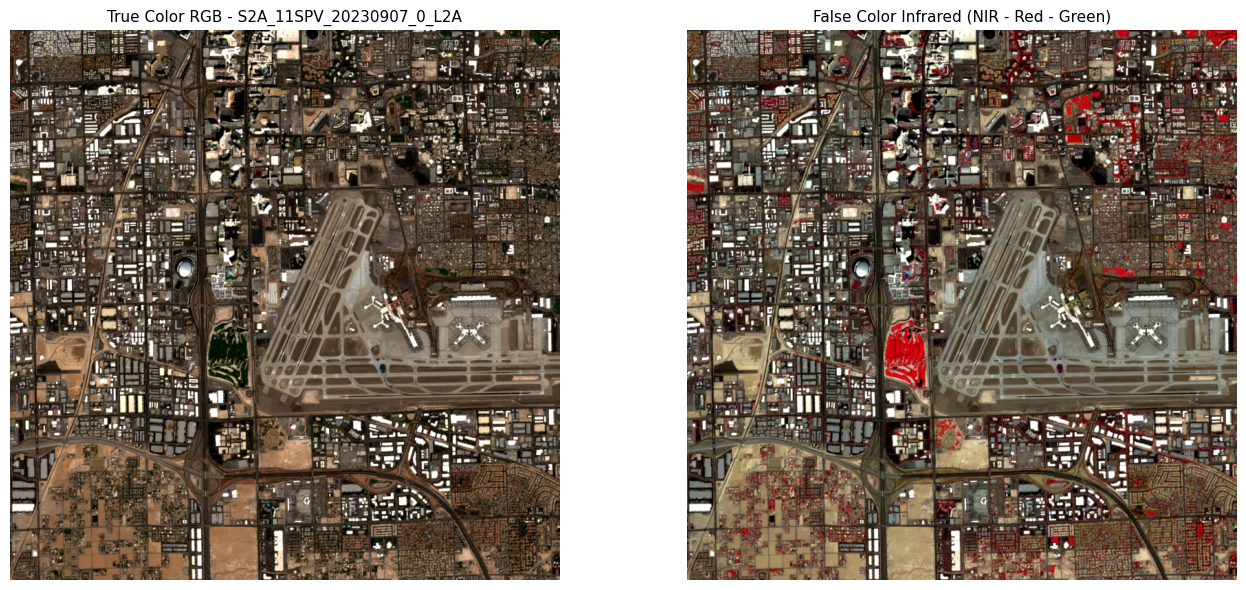

PyTorch tensor shape for ML models: torch.Size([4, 800, 800])


In [9]:
# 5. Visualize True Color (RGB) and False Color Infrared (CIR)
rgb = np.dstack([bands["Red"], bands["Green"], bands["Blue"]])
cir = np.dstack([bands["NIR"], bands["Red"], bands["Green"]])

# 2nd to 98th percentile contrast stretch with gamma correction for optical clarity
rgb_stretched = (
    np.clip(
        (rgb - np.percentile(rgb, 2))
        / (np.percentile(rgb, 98) - np.percentile(rgb, 2)),
        0.0,
        1.0,
    )
    ** 0.85
)
cir_stretched = (
    np.clip(
        (cir - np.percentile(cir, 2))
        / (np.percentile(cir, 98) - np.percentile(cir, 2)),
        0.0,
        1.0,
    )
    ** 0.85
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), facecolor="white")

axes[0].imshow(rgb_stretched)
axes[0].set_title(f"True Color RGB - {record['scenes/scene_id']}", fontsize=11)
axes[0].axis("off")

axes[1].imshow(cir_stretched)
axes[1].set_title("False Color Infrared (NIR - Red - Green)", fontsize=11)
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Downstream ML note: Convert numpy stack to PyTorch tensor for foundation models (e.g., Prithvi, Clay)
tensor = torch.from_numpy(np.stack(list(bands.values()), axis=0))
print(f"PyTorch tensor shape for ML models: {tensor.shape}")